# Jour 5 — Visualisation interactive

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1712/chapter/3347), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Préparation
Les lignes sont des articles de commandes ; Order ID peut donc se répéter légitimement. Suppression des doublons exacts seulement. Les dates sont converties et les codes postaux restent des identifiants. Les marges agrégées sont somme(Profit)/somme(Sales), sans moyenne non pondérée des marges de lignes.

In [2]:
df = pd.read_excel(course_file("Datasets-DA-Bootcamp-2-", "Week 5 - Data Processing/W5D5 - Mini-project - bis/US Superstore data.xls"))
print("Avant nettoyage", df.shape, "doublons", df.duplicated().sum())
display(df.isna().sum().to_frame("manquants"))
df = df.drop_duplicates().copy()
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
# Les codes postaux sont des identifiants ; une absence ne signifie pas zéro.
df["Postal Code"] = df["Postal Code"].astype("Int64").astype("string").str.zfill(5)
assert df[["Sales", "Profit", "Order Date"]].notna().all().all()
df["Profit Margin"] = df["Profit"].div(df["Sales"].replace(0,np.nan))*100
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month"] = df["Order Date"].dt.to_period("M")
print("Après nettoyage",df.shape)
display(df.head())

Avant nettoyage (9994, 21) doublons 0


/var/folders/tn/21t5tzkd48z82_wfylsc12l00000gn/T/ipykernel_55765/4250579115.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(course_file("Datasets-DA-Bootcamp-2-", "Week 5 - Data Processing/W5D5 - Mini-project - bis/US Superstore data.xls"))


,manquants
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Après nettoyage (9994, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin,Order Year,Order Month,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,2016,11,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,2016,11,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,2016,6,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,2015,10,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,2015,10,2015-10


## Courbe temporelle interactive

interactive(children=(Dropdown(description='Category', options=('All', 'Furniture', 'Office Supplies', 'Techno…

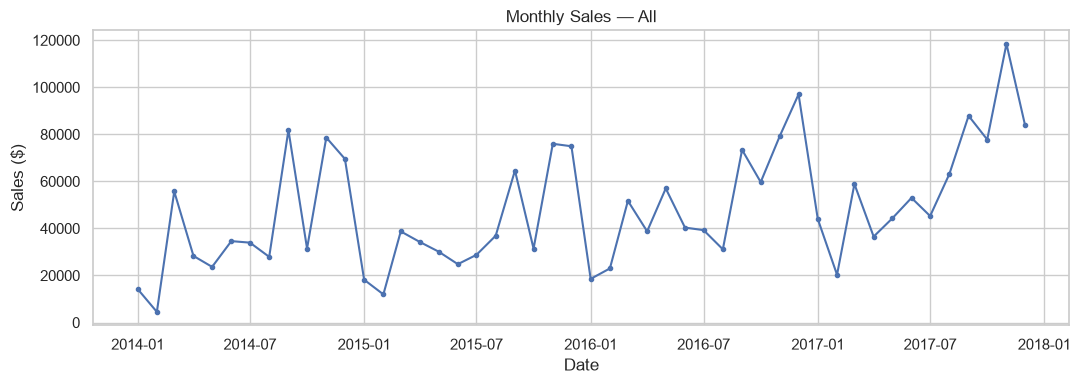

In [3]:
import ipywidgets as widgets
from ipywidgets import interact

def plot_monthly(category="All"):
    subset=df if category=="All" else df.loc[df["Category"].eq(category)]
    monthly=subset.groupby("Month")["Sales"].sum()
    plt.figure(figsize=(11,4));plt.plot(monthly.index.to_timestamp(),monthly.values,marker=".")
    plt.title(f"Monthly Sales — {category}");plt.xlabel("Date");plt.ylabel("Sales ($)");plt.tight_layout();plt.show()
interact(plot_monthly,category=widgets.Dropdown(options=["All"]+sorted(df["Category"].unique()),description="Category"));
# Vue statique disponible dans GitHub même sans noyau interactif.
plot_monthly("All")


## Carte interactive par pays
Le fichier US Superstore ne contient qu’un pays. La carte affiche honnêtement cette seule couverture ; elle ne permet pas de comparer des pays. Le filtre annuel permet d’explorer les ventes observées. Plotly est utilisé pour la carte géographique interactive ; Matplotlib réalise la courbe demandée.

In [4]:
import plotly.express as px
country_year=df.groupby(["Order Year","Country"],as_index=False)["Sales"].sum()
assert set(country_year["Country"])=={"United States"}
country_year["ISO3"]="USA"
fig=px.choropleth(country_year,locations="ISO3",color="Sales",hover_name="Country",animation_frame="Order Year",scope="world",color_continuous_scale="Blues",title="US Superstore — Sales by Country and Year")
fig.show()
# Tableau de repli consultable dans GitHub.
display(country_year)

,Order Year,Country,Sales,ISO3
0,2014,United States,484247.4981,USA
1,2015,United States,470532.5090,USA
2,2016,United States,609205.5980,USA
3,2017,United States,733215.2552,USA


## Top 10 produits par ventes

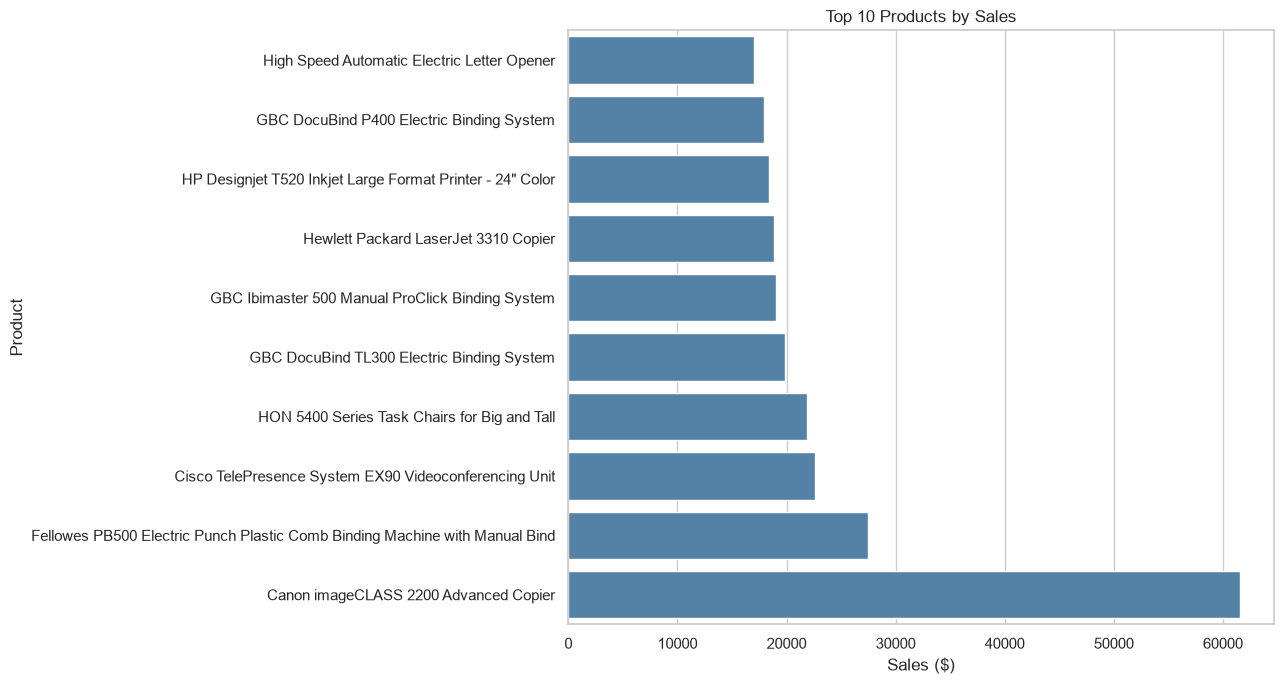

In [5]:
products=df.groupby("Product Name")["Sales"].sum().nlargest(10).sort_values()
plt.figure(figsize=(13,7));sns.barplot(x=products.values,y=products.index,color="steelblue")
plt.xlabel("Sales ($)");plt.ylabel("Product");plt.title("Top 10 Products by Sales");plt.tight_layout();plt.show()

## Remise et profit

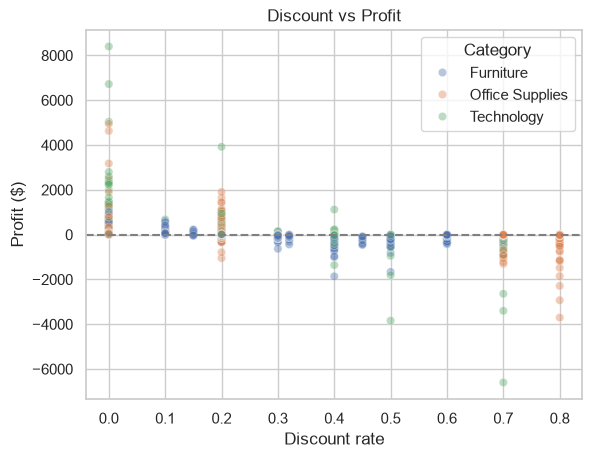

,count,mean,sum
Discount,,,
0.00,4798,66.900292,320987.6032
0.10,94,96.055074,9029.1770
0.15,52,27.288298,1418.9915
0.20,3657,24.702572,90337.3060
0.30,227,-45.679636,-10369.2774
0.32,27,-88.560656,-2391.1377
0.40,206,-111.927429,-23057.0504
0.45,11,-226.646464,-2493.1111
0.50,66,-310.703456,-20506.4281


In [6]:
sns.scatterplot(data=df,x="Discount",y="Profit",hue="Category",alpha=.4)
plt.axhline(0,color="grey",ls="--");plt.title("Discount vs Profit");plt.xlabel("Discount rate");plt.ylabel("Profit ($)");plt.show()
display(df.groupby("Discount")["Profit"].agg(["count","mean","sum"]))

## Comparaison et observations
Matplotlib permet de suivre la saisonnalité et les différences de volumes selon les catégories avec contrôle fin des axes. Seaborn rend les catégories et relations plus rapides à comparer grâce à hue et aux fonctions statistiques. Les outils partagent la même base Matplotlib ; les widgets exigent un noyau actif. La carte montre la restriction américaine du jeu, tandis que les classements produits et le nuage profit-remise guident des audits ciblés. Une corrélation remise-perte ne démontre pas que la remise seule cause la perte. Pour partager une carte autonome, exporter le graphique Plotly en HTML ; le notebook reste le livrable principal.